<a href="https://colab.research.google.com/github/Ravi-ranjan1801/Data-Warehousing-Mining-Lab/blob/main/DWM_Lab_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab - 08 (Similarity and Dissimilarity Measures)**

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io
import os

from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded))

DATA_DIR = "/content/dwm_data"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall(DATA_DIR)

print("Files extracted successfully!")

print(os.listdir(DATA_DIR))

Saving DWM_Practical_Datasets.zip to DWM_Practical_Datasets (1).zip
Files extracted successfully!
['10_text_mining_documents.csv', '09_clustering_kmeans_kmedoids.csv', '02_normalization_discretization_students.csv', '05_apriori_market_basket.csv', '01_missing_values_patient_dataset.csv', '04_olap_sales_dataset.csv', '08_classification_regression_models_cv_ann.csv', 'README_2_Hour_Lab_Instructions.txt', '06_entropy_information_gain_gini.csv', '03_pca_attribute_selection_students.csv', '07_linear_regression_houses.csv']


In [16]:
file_path = os.path.join(
    DATA_DIR,
    "05_apriori_market_basket.csv"
)

basket = pd.read_csv(file_path)

print("Dataset Shape:", basket.shape)

display(basket.head())

Dataset Shape: (80, 2)


,Transaction_ID,Items
0,T001,Biscuits;Bread;Butter;Coffee;Milk
1,T002,Apples;Milk
2,T003,Cheese;Coffee
3,T004,Biscuits;Butter;Coffee;Tea
4,T005,Bread;Butter


In [17]:
transactions = basket['Items'].fillna('').apply(
    lambda x: [item.strip() for item in x.split(';') if item.strip()]
)

all_items = sorted(set(
    item
    for transaction in transactions
    for item in transaction
))

binary_data = pd.DataFrame(
    0,
    index=basket['Transaction_ID'],
    columns=all_items,
    dtype=int
)

for tid, items in zip(basket['Transaction_ID'], transactions):
    for item in items:
        binary_data.loc[tid, item] = 1

binary_data.index.name = 'Customer_ID'

print("Binary Customer-Item Matrix:")

display(binary_data.head(10))

Binary Customer-Item Matrix:


,Apples,Bananas,Biscuits,Bread,Butter,Cheese,Coffee,Eggs,Milk,Tea
Customer_ID,,,,,,,,,,
T001,0,0,1,1,1,0,1,0,1,0
T002,1,0,0,0,0,0,0,0,1,0
T003,0,0,0,0,0,1,1,0,0,0
T004,0,0,1,0,1,0,1,0,0,1
T005,0,0,0,1,1,0,0,0,0,0
T006,0,0,1,1,1,0,0,0,0,0
T007,0,0,1,0,1,0,0,1,0,1
T008,0,0,1,1,1,0,0,0,0,1
T009,0,0,0,1,1,0,0,0,1,0


In [18]:
def calculate_similarity(a, b):

    a = np.array(a)
    b = np.array(b)

    M11 = np.sum((a == 1) & (b == 1))
    M00 = np.sum((a == 0) & (b == 0))
    M10 = np.sum((a == 1) & (b == 0))
    M01 = np.sum((a == 0) & (b == 1))

    smc = (M11 + M00) / (
        M11 + M00 + M10 + M01
    )

    denominator = M11 + M10 + M01

    jaccard = (
        M11 / denominator
        if denominator > 0
        else np.nan
    )

    return smc, jaccard

In [19]:
customer1 = binary_data.loc['T001']

customer2 = binary_data.loc['T002']

smc, jaccard = calculate_similarity(
    customer1,
    customer2
)

print("SMC Similarity:", round(smc, 4))

print("Jaccard Similarity:", round(jaccard, 4))

SMC Similarity: 0.5
Jaccard Similarity: 0.1667


In [20]:
n = len(binary_data)

smc_matrix = np.zeros((n, n))

jaccard_matrix = np.zeros((n, n))

for i in range(n):

    for j in range(n):

        smc, jac = calculate_similarity(
            binary_data.iloc[i],
            binary_data.iloc[j]
        )

        smc_matrix[i, j] = smc

        jaccard_matrix[i, j] = jac

In [21]:
smc_df = pd.DataFrame(
    smc_matrix,
    index=binary_data.index,
    columns=binary_data.index
)

jaccard_df = pd.DataFrame(
    jaccard_matrix,
    index=binary_data.index,
    columns=binary_data.index
)

print("SMC Similarity Matrix (First 10 Customers):")

display(smc_df.iloc[:10, :10].round(3))

print("Jaccard Similarity Matrix (First 10 Customers):")

display(jaccard_df.iloc[:10, :10].round(3))

SMC Similarity Matrix (First 10 Customers):


Customer_ID,T001,T002,T003,T004,T005,T006,T007,T008,T009,T010
Customer_ID,,,,,,,,,,
T001,1.0,0.5,0.5,0.7,0.7,0.8,0.5,0.7,0.8,0.5
T002,0.5,1.0,0.6,0.4,0.6,0.5,0.4,0.4,0.7,0.8
T003,0.5,0.6,1.0,0.6,0.6,0.5,0.4,0.4,0.5,0.6
T004,0.7,0.4,0.6,1.0,0.6,0.7,0.8,0.8,0.5,0.4
T005,0.7,0.6,0.6,0.6,1.0,0.9,0.6,0.8,0.9,0.6
T006,0.8,0.5,0.5,0.7,0.9,1.0,0.7,0.9,0.8,0.5
T007,0.5,0.4,0.4,0.8,0.6,0.7,1.0,0.8,0.5,0.6
T008,0.7,0.4,0.4,0.8,0.8,0.9,0.8,1.0,0.7,0.4
T009,0.8,0.7,0.5,0.5,0.9,0.8,0.5,0.7,1.0,0.7


Jaccard Similarity Matrix (First 10 Customers):


Customer_ID,T001,T002,T003,T004,T005,T006,T007,T008,T009,T010
Customer_ID,,,,,,,,,,
T001,1.000,0.167,0.167,0.500,0.400,0.600,0.286,0.50,0.600,0.167
T002,0.167,1.000,0.000,0.000,0.000,0.000,0.000,0.00,0.250,0.333
T003,0.167,0.000,1.000,0.200,0.000,0.000,0.000,0.00,0.000,0.000
T004,0.500,0.000,0.200,1.000,0.200,0.400,0.600,0.60,0.167,0.000
T005,0.400,0.000,0.000,0.200,1.000,0.667,0.200,0.50,0.667,0.000
T006,0.600,0.000,0.000,0.400,0.667,1.000,0.400,0.75,0.500,0.000
T007,0.286,0.000,0.000,0.600,0.200,0.400,1.000,0.60,0.167,0.200
T008,0.500,0.000,0.000,0.600,0.500,0.750,0.600,1.00,0.400,0.000
T009,0.600,0.250,0.000,0.167,0.667,0.500,0.167,0.40,1.000,0.250


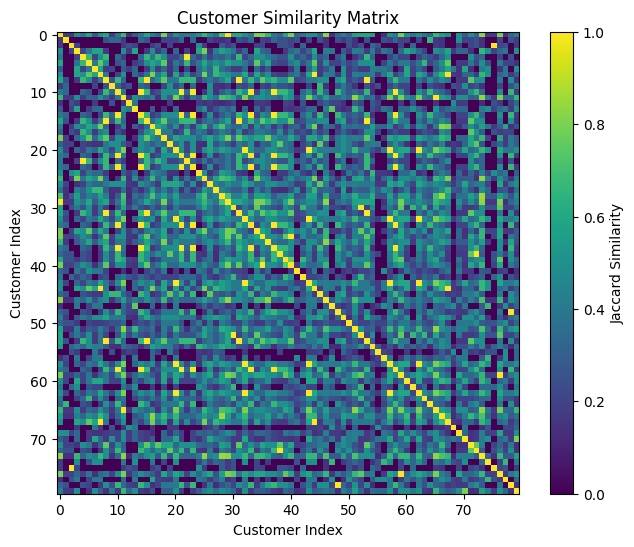

In [22]:
plt.figure(figsize=(8, 6))

plt.imshow(jaccard_matrix)

plt.colorbar(label='Jaccard Similarity')

plt.title('Customer Similarity Matrix')

plt.xlabel('Customer Index')

plt.ylabel('Customer Index')

plt.show()

In [23]:
patient_path = os.path.join(
    DATA_DIR,
    "01_missing_values_patient_dataset.csv"
)

patients = pd.read_csv(patient_path)

print("Dataset Shape:", patients.shape)

display(patients.head())

print("\nMissing Values:")

print(patients.isnull().sum())

Dataset Shape: (80, 8)


,Record_ID,Age,Temperature_C,Heart_Rate,Gender,Fever,Cough,Diagnosis
0,P001,72.0,37.7,87.0,Male,No,No,Cold
1,P002,23.0,37.8,90.0,Male,Yes,Yes,Cold
2,P003,61.0,38.1,NaN,Male,No,No,Flu
3,P004,19.0,38.2,81.0,Female,No,No,Flu
4,P005,NaN,38.0,115.0,Female,Yes,Yes,Cold



Missing Values:
Record_ID        0
Age              8
Temperature_C    9
Heart_Rate       6
Gender           4
Fever            4
Cough            0
Diagnosis        0
dtype: int64


In [24]:
patient_clean = patients.copy()

numeric_cols = [
    'Age',
    'Temperature_C',
    'Heart_Rate'
]

binary_cols = [
    'Gender',
    'Fever',
    'Cough'
]

nominal_cols = [
    'Diagnosis'
]

categorical_cols = binary_cols + nominal_cols

for col in numeric_cols:

    patient_clean[col] = patient_clean[col].fillna(
        patient_clean[col].median()
    )

for col in categorical_cols:

    patient_clean[col] = patient_clean[col].fillna(
        patient_clean[col].mode()[0]
    )

print("Missing values after imputation:")

print(patient_clean.isnull().sum())

Missing values after imputation:
Record_ID        0
Age              0
Temperature_C    0
Heart_Rate       0
Gender           0
Fever            0
Cough            0
Diagnosis        0
dtype: int64


In [25]:
X_num = patient_clean[numeric_cols].values

n = len(X_num)

num_dist_matrix = np.zeros((n, n))

for col in range(len(numeric_cols)):

    values = X_num[:, col]

    value_range = values.max() - values.min()

    if value_range == 0:
        continue

    for i in range(n):

        for j in range(n):

            distance = abs(
                values[i] - values[j]
            ) / value_range

            num_dist_matrix[i, j] += distance

num_dist_matrix = num_dist_matrix / len(numeric_cols)

print("Normalized Numerical Dissimilarity Matrix:")

display(
    pd.DataFrame(
        num_dist_matrix[:10, :10],
        index=patient_clean['Record_ID'].iloc[:10],
        columns=patient_clean['Record_ID'].iloc[:10]
    ).round(3)
)

Normalized Numerical Dissimilarity Matrix:


Record_ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010
Record_ID,,,,,,,,,,
P001,0.000,0.312,0.112,0.393,0.340,0.228,0.554,0.105,0.408,0.254
P002,0.312,0.000,0.264,0.110,0.256,0.510,0.293,0.323,0.312,0.373
P003,0.112,0.264,0.000,0.290,0.249,0.330,0.538,0.123,0.382,0.228
P004,0.393,0.110,0.290,0.000,0.323,0.620,0.312,0.346,0.403,0.483
P005,0.340,0.256,0.249,0.323,0.000,0.394,0.549,0.351,0.393,0.160
P006,0.228,0.510,0.330,0.620,0.394,0.000,0.524,0.332,0.368,0.243
P007,0.554,0.293,0.538,0.312,0.549,0.524,0.000,0.527,0.156,0.580
P008,0.105,0.323,0.123,0.346,0.351,0.332,0.527,0.000,0.419,0.265
P009,0.408,0.312,0.382,0.403,0.393,0.368,0.156,0.419,0.000,0.424


In [26]:
patient_clean['Gender'] = patient_clean['Gender'].map({
    'Female': 0,
    'Male': 1
})

patient_clean['Fever'] = patient_clean['Fever'].map({
    'No': 0,
    'Yes': 1
})

patient_clean['Cough'] = patient_clean['Cough'].map({
    'No': 0,
    'Yes': 1
})

display(patient_clean.head())

,Record_ID,Age,Temperature_C,Heart_Rate,Gender,Fever,Cough,Diagnosis
0,P001,72.0,37.7,87.0,1,0,0,Cold
1,P002,23.0,37.8,90.0,1,1,1,Cold
2,P003,61.0,38.1,88.0,1,0,0,Flu
3,P004,19.0,38.2,81.0,0,0,0,Flu
4,P005,42.5,38.0,115.0,0,1,1,Cold


In [27]:
distance_components = []

# Numerical attributes
for col in numeric_cols:

    values = patient_clean[col].values.astype(float)

    value_range = values.max() - values.min()

    if value_range == 0:

        distances = np.zeros((len(values), len(values)))

    else:

        distances = (
            np.abs(values[:, None] - values[None, :])
            / value_range
        )

    distance_components.append(distances)


# Binary attributes
for col in binary_cols:

    values = patient_clean[col].values

    distances = (
        values[:, None] != values[None, :]
    ).astype(float)

    distance_components.append(distances)


# Nominal attributes
for col in nominal_cols:

    values = patient_clean[col].values

    distances = (
        values[:, None] != values[None, :]
    ).astype(float)

    distance_components.append(distances)


# Average all attribute dissimilarities
mixed_dist_matrix = np.mean(
    np.stack(distance_components),
    axis=0
)

print("Mixed Attribute Dissimilarity Matrix:")

Mixed Attribute Dissimilarity Matrix:


In [28]:
mixed_df = pd.DataFrame(
    mixed_dist_matrix,
    index=patient_clean['Record_ID'],
    columns=patient_clean['Record_ID']
)

display(mixed_df.iloc[:10, :10].round(3))

Record_ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010
Record_ID,,,,,,,,,,
P001,0.000,0.419,0.191,0.454,0.574,0.526,0.666,0.473,0.603,0.395
P002,0.419,0.000,0.542,0.619,0.253,0.647,0.554,0.281,0.277,0.446
P003,0.191,0.542,0.000,0.267,0.678,0.570,0.516,0.624,0.449,0.383
P004,0.454,0.619,0.267,0.000,0.567,0.552,0.276,0.577,0.601,0.636
P005,0.574,0.253,0.678,0.567,0.000,0.454,0.521,0.151,0.454,0.497
P006,0.526,0.647,0.570,0.552,0.454,0.000,0.367,0.428,0.586,0.533
P007,0.666,0.554,0.516,0.276,0.521,0.367,0.000,0.511,0.352,0.820
P008,0.473,0.281,0.624,0.577,0.151,0.428,0.511,0.000,0.465,0.542
P009,0.603,0.277,0.449,0.601,0.454,0.586,0.352,0.465,0.000,0.468


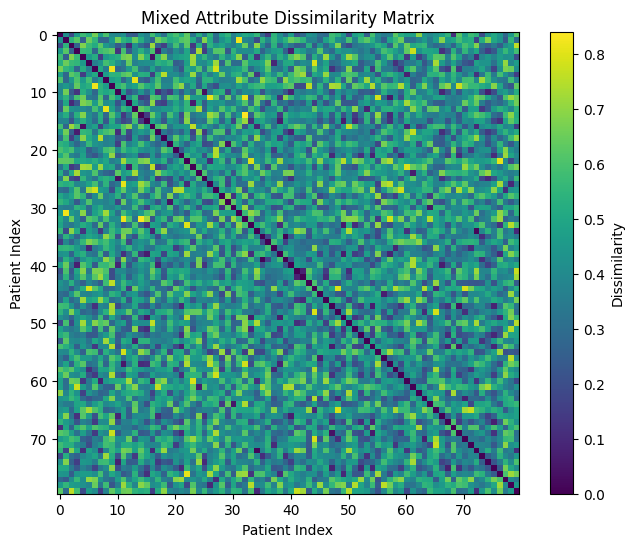

In [29]:
plt.figure(figsize=(8, 6))

plt.imshow(mixed_dist_matrix)

plt.colorbar(label='Dissimilarity')

plt.title('Mixed Attribute Dissimilarity Matrix')

plt.xlabel('Patient Index')

plt.ylabel('Patient Index')

plt.show()